# Ecobici — 02. Modelo estocástico por estación (Etapa 2)

Modelo de cada estación de la subred, contraste de sus supuestos con los datos, estimación de parámetros y medidas de falla: estación vacía (viaje negado) y estación llena (usuario que no puede devolver).

- Subred: Buenavista (271-272, 273-274) y Reforma (014, 027, 018).
- Periodo: septiembre 2026, 19 días hábiles. Para validar se usan los 13 meses de `trips_12m.parquet` (septiembre 2025 a septiembre 2026).
- Insumos: `data_cleaning.ipynb` (datos limpios) y el EDA (`eda.ipynb`, `eda_b.ipynb`).

## 1. Modelo

El estado es el número de bicis ancladas en la estación, $X(t) \in \{0, 1, \dots, N\}$, con $N$ = docks. Es una cadena de Markov en tiempo continuo con estados finitos.

Caso base (una bici a la vez). Es un proceso de nacimiento y muerte truncado en $N$: los procesos de nacimiento y muerte se definen sobre $\mathbb{N}$, y aquí el espacio se corta porque la estación no puede tener más de $N$ bicis. En la hora $h$ las tasas dependen del estado:

$$\lambda_n(h) = \begin{cases} \lambda(h) & n < N \\ 0 & n = N \end{cases} \qquad \mu_n(h) = \begin{cases} \mu(h) & n > 0 \\ 0 & n = 0 \end{cases}$$

- $\lambda(h)$: devoluciones por hora que llegan a la estación (nacimientos).
- $\mu(h)$: usuarios por hora que llegan a sacar una bici (muertes).
- Una devolución con $n = N$ o un retiro con $n = 0$ no cambian el estado: son rechazos.

Este generador es el mismo que el de una cola M/M/1/N si se ve a las bicis como clientes, a las devoluciones como llegadas y a los retiros como servicios. Pero aquí no hay servidor: los retiros los generan usuarios que llegan con tasa $\mu(h)$. Por eso las tasas se definen directamente por estado y el nombre M/M/1/N solo se usa como referencia.

Extensión con lotes (sección 1.2). Los datos muestran que a veces llegan varias personas juntas. Se modela así: los lotes llegan con tasa $\lambda(h)/b$ y cada lote trae $K$ bicis, con $K$ geométrica de media $b$. El estado salta de $n$ a $\min(n+K, N)$, y lo que no cabe se rechaza. Los retiros funcionan igual, hacia abajo. Con $b = 1$ se recupera el caso base.

Solución: la estación arranca a las 5:00 con $x_0$ bicis. Cada hora, con tasas constantes, se resuelve $p'(t) = p(t)\,Q_h$ (Kolmogorov hacia adelante), y cada hora parte de la distribución con la que terminó la anterior. No se usa el estado estable porque las tasas cambian mucho durante el día y porque la solución estable no depende de $x_0$, que es lo que decide el operador.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import expm
from scipy.optimize import brentq

DIR_TABLAS, DIR_FIG = Path("outputs/tablas"), Path("outputs/figuras")
SUBRED = {"271-272": "Buenavista", "273-274": "Buenavista", "014": "Reforma", "027": "Reforma", "018": "Reforma"}
ORDEN, HORAS = list(SUBRED), np.arange(5, 24)
COLORES = {"Buenavista": "#d1495b", "Reforma": "#2e86ab"}

df = pd.read_parquet("data/clean/trips_2026-09.parquet")
INFO = pd.DataFrame(json.loads(Path("data/raw/station_information.json").read_text())["data"]["stations"]).set_index("short_name")
DOCKS = INFO["capacity"]

dias = df.loc[df.es_habil, "fecha"].drop_duplicates().sort_values()
n_dias = len(dias)

# Retiros por fecha-hora de retiro; devoluciones por fecha-hora de arribo
m_ret = df.es_habil & df.en_horario & df.retiro_subred
m_dev = df.arribo_subred & df.arribo.dt.normalize().isin(dias) & df.hora_arribo.between(5, 23)
eventos = {
    "retiro": pd.DataFrame({"estacion": df.loc[m_ret, "Ciclo_Estacion_Retiro"].astype(str), "t": df.loc[m_ret, "retiro"]}),
    "devolucion": pd.DataFrame({"estacion": df.loc[m_dev, "Ciclo_EstacionArribo"].astype(str), "t": df.loc[m_dev, "arribo"]}),
}

# Conteos por intervalo de 15 min (rejilla completa: los intervalos sin viajes valen 0)
rejilla = pd.MultiIndex.from_product([ORDEN, dias, HORAS, range(4)], names=["estacion", "fecha", "hora", "cuarto"])
conteos = {
    k: e.groupby([e.estacion, e.t.dt.normalize().rename("fecha"), e.t.dt.hour.rename("hora"),
                  (e.t.dt.minute // 15).rename("cuarto")]).size().reindex(rejilla, fill_value=0)
    for k, e in eventos.items()
}

### 1.1 ¿Las llegadas son Poisson?

Antes solo se reportaba el CV (desviación estándar / media) de los tiempos entre llegadas. Si los tiempos son exponenciales, el CV vale 1. Eso es un indicador descriptivo, no una prueba: no dice qué tan lejos de 1 es demasiado.

Ahora se agregan dos pruebas exactas. Usan esta propiedad: si en una hora llegaron $n$ personas y el proceso es Poisson con tasa constante, los $n$ tiempos de llegada son $n$ uniformes independientes en la hora, sea cual sea la tasa.

1. Prueba de CV por Monte Carlo. Para cada hora con $n \ge 6$ llegadas se simulan 5,000 horas con $n$ uniformes y se obtiene la distribución del CV bajo Poisson. El p-valor (bilateral) dice qué tan raro es el CV observado. Si el modelo es correcto, cerca del 5 % de las horas debería rechazar al 5 %.
2. Kolmogorov–Smirnov. Se compara la posición dentro de la hora (minuto y segundo / 3600) de todas las llegadas contra una uniforme en [0, 1).

Solo se usan horas sin ningún intervalo de 15 min vacío, para que una estación vacía o llena no se confunda con falta de llegadas. También se reporta la dispersión entre días (varianza / media de los conteos por hora; vale 1 si todos los días tienen la misma tasa).

In [2]:
rng = np.random.default_rng(2026)
N_MC = 5000
_cv_nulo = {}

def cv_nulo(n):
    """CV de los tiempos entre n llegadas uniformes en una hora, simulado N_MC veces (distribución bajo Poisson)."""
    if n not in _cv_nulo:
        d = np.diff(np.sort(rng.random((N_MC, n)), axis=1), axis=1)
        _cv_nulo[n] = d.std(axis=1, ddof=1) / d.mean(axis=1)
    return _cv_nulo[n]

filas = []
for proceso, c in conteos.items():
    sin_hueco = c.groupby(["estacion", "fecha", "hora"]).min() > 0          # horas sin ningún intervalo de 15 min vacío
    por_hora = c.groupby(["estacion", "fecha", "hora"]).sum()
    e = eventos[proceso].sort_values("t")
    e = e.assign(fecha=e.t.dt.normalize(), hora=e.t.dt.hour, u=(e.t.dt.minute * 60 + e.t.dt.second) / 3600)
    e = e[sin_hueco.reindex(pd.MultiIndex.from_frame(e[["estacion", "fecha", "hora"]])).to_numpy()]
    for est in ORDEN:
        x = por_hora.loc[est].unstack("hora")
        D = (x.var() / x.mean())[x.mean() >= 5]
        s = e[e.estacion == est]
        cvs, pvs = [], []
        for _, g in s.groupby(["fecha", "hora"]):
            if len(g) < 6:
                continue
            d = np.diff(np.sort(g.u.to_numpy()))
            cv = d.std(ddof=1) / d.mean()
            nulo = cv_nulo(len(g))
            cvs.append(cv)
            pvs.append(min(1, 2 * min((nulo >= cv).mean(), (nulo <= cv).mean())))
        ks = stats.kstest(s.u, "uniform")
        filas.append({"estación": est, "proceso": proceso,
                      "dispersión var/media": D.median(),
                      "CV mediano": np.median(cvs),
                      "horas probadas": len(pvs),
                      "% horas que rechazan (5 %)": 100 * np.mean(np.array(pvs) < 0.05),
                      "KS: D": ks.statistic, "KS: p": ks.pvalue})

justificacion = pd.DataFrame(filas)
justificacion.round(4).to_csv(DIR_TABLAS / "justificacion_mm1n.csv", index=False)
justificacion.round({"dispersión var/media": 2, "CV mediano": 2, "% horas que rechazan (5 %)": 1, "KS: D": 3}) \
             .assign(**{"KS: p": justificacion["KS: p"].map("{:.1e}".format)})

,estación,proceso,dispersión var/media,CV mediano,horas probadas,% horas que rechazan (5 %),KS: D,KS: p
0,271-272,retiro,2.48,1.07,250,24.8,0.029,2.4e-06
1,273-274,retiro,7.58,1.00,67,25.4,0.076,7.5e-08
2,014,retiro,2.02,1.00,186,13.4,0.022,9.3e-02
3,027,retiro,2.11,0.98,229,5.7,0.024,1.4e-02
4,018,retiro,1.25,0.97,200,9.5,0.014,5.2e-01
5,271-272,devolucion,3.31,1.06,226,23.5,0.038,1.6e-15
6,273-274,devolucion,3.78,1.06,123,21.1,0.015,4.3e-01
7,014,devolucion,1.75,1.00,205,13.7,0.024,1.2e-02
8,027,devolucion,1.44,0.98,260,5.8,0.037,3.9e-06
9,018,devolucion,1.27,0.97,223,7.2,0.031,1.0e-03


**Resultados**

- El CV mediano está entre 0.97 y 1.07, pero la prueba de CV rechaza en más horas de las esperadas: entre 21 % y 25 % en Buenavista y entre 6 % y 14 % en Reforma (lo esperado es 5 %).
- KS rechaza la uniformidad en 7 de las 10 series, aunque la distancia es chica (D de 0.014 a 0.076). Con miles de llegadas cualquier diferencia pequeña sale significativa.
- La dispersión entre días va de 1.25 a 7.58: la tasa cambia de un día a otro.
- Poisson es una buena primera aproximación, pero no es exacto, sobre todo en Buenavista. La sección 1.2 busca la causa.

### 1.2 Llegadas en lote

Si varias personas llegan juntas (un grupo de amigos, la gente que baja del mismo tren en Buenavista), habrá más tiempos muy cortos entre llegadas de los que da Poisson.

1. Para cada rango de tiempo entre llegadas se divide la frecuencia observada entre la esperada con Poisson (usando la tasa de esa hora). Si vale 1, no hay exceso.
2. Se estima el tamaño medio de lote $b$. Bajo el modelo con lotes geométricos, una fracción $1 - 1/b$ de los tiempos son dentro de un mismo lote (casi cero) y el resto son entre lotes, exponenciales con tasa $r/b$. Entonces

$$P(\text{tiempo} \le 20\text{ s}) = \left(1 - \tfrac{1}{b}\right) + \tfrac{1}{b}\left(1 - e^{-20\, r / b}\right),$$

y se despeja $b$ igualando con la fracción observada. Se usa 20 s porque es donde se acaba el exceso (tabla de abajo).

In [3]:
UMBRAL_LOTE = 20          # segundos
RANGOS = [0, 5, 10, 20, 30, 60, 120]

filas_r, filas_b = [], []
for proceso, e in eventos.items():
    e = e.assign(fecha=e.t.dt.normalize(), hora=e.t.dt.hour).sort_values("t")
    g = e.groupby(["estacion", "fecha", "hora"])
    e["gap"] = g.t.diff().dt.total_seconds()
    e["r"] = g.t.transform("size") / 3600                   # tasa de esa hora, en llegadas por segundo
    e = e[e.gap.notna()]

    # 1) ¿Hasta dónde hay más tiempos cortos de los que da Poisson? (observados / esperados por rango)
    fila = {"proceso": proceso}
    for a, b in zip(RANGOS[:-1], RANGOS[1:]):
        obs = ((e.gap > a) & (e.gap <= b)).mean()
        esp = (np.exp(-e.r * a) - np.exp(-e.r * b)).mean()
        fila[f"{a}–{b} s"] = obs / esp
    filas_r.append(fila)

    # 2) Tamaño medio de lote b: fracción de tiempos <= 20 s = (1 - 1/b) + (1/b)(1 - exp(-r/b * 20))
    for est in ORDEN:
        s = e[e.estacion == est]
        obs = (s.gap <= UMBRAL_LOTE).mean()
        f = lambda b: ((1 - 1 / b) + (1 - np.exp(-s.r / b * UMBRAL_LOTE)) / b).mean() - obs
        filas_b.append({"estacion": est, "proceso": proceso, "tiempos <= 20 s (obs.)": obs,
                        "tiempos <= 20 s (Poisson)": f(1.0) + obs, "b": brentq(f, 1.0, 10) if f(1.0) < 0 else 1.0})

display(pd.DataFrame(filas_r).set_index("proceso").round(2))
lotes = pd.DataFrame(filas_b)
lotes.round(3).to_csv(DIR_TABLAS / "lotes.csv", index=False)
B = lotes.set_index(["estacion", "proceso"]).b
lotes.pivot(index="estacion", columns="proceso", values="b").reindex(ORDEN).round(2)

,0–5 s,5–10 s,10–20 s,20–30 s,30–60 s,60–120 s
proceso,,,,,,
retiro,1.96,1.42,1.23,1.02,0.88,0.84
devolucion,1.48,1.25,1.08,0.95,0.88,0.88


proceso,devolucion,retiro
estacion,,
271-272,1.23,1.37
273-274,1.17,1.27
014,1.11,1.04
027,1.05,1.04
018,1.07,1.05


**Resultados**

- Hay casi el doble de tiempos de 0 a 5 s de los que da Poisson (1.96 en retiros y 1.48 en devoluciones), el exceso baja de 5 a 20 s y desaparece después de 20 s.
- Los lotes están en Buenavista: $b$ = 1.37 en retiros de la 271-272 y 1.27 en la 273-274. En Reforma $b$ está entre 1.04 y 1.11, casi una bici a la vez.
- Esto explica por qué las pruebas de 1.1 rechazan más en Buenavista. El modelo final usa estos $b$.

### 1.3 Estimación de λ y μ

Para cada estación y hora $h$, con $D = 19$ días hábiles y $N_{d,h}$ = llegadas del día $d$ en la hora $h$:

$$\hat\lambda(h) = \frac{1}{D}\sum_{d=1}^{D} N_{d,h}$$

(igual para $\hat\mu(h)$ con los retiros). Es el estimador de máxima verosimilitud de la tasa de un proceso de Poisson y también el de momentos con lotes, porque la media por hora sigue siendo la tasa.

Error estándar: con Poisson sería $\sqrt{\hat\lambda / D}$, pero como la tasa cambia entre días se usa el error entre días, $s / \sqrt{D}$ ($s$ = desviación estándar de $N_{d,h}$ entre días). El intervalo de 95 % es $\hat\lambda \pm 1.96\, s/\sqrt{D}$.

Horas hueco. En algunas horas la estación pasó vacía (o llena) y la demanda no quedó registrada. Una hora se revisa si cumple las dos condiciones:

1. Tiene una tasa de 8 o más por hora y al menos 10 puntos más de intervalos de 15 min en cero de los que esperaría el modelo con lotes, $e^{-\lambda/(4b)}$.
2. No la contradicen las estaciones vecinas (a 150 m o menos). Si la estación estaba vacía, quien llega camina a la vecina, y la vecina debería tener igual o más actividad en esos intervalos. Si la vecina tiene significativamente menos (Mann–Whitney unilateral, p < 0.05), el cero es de baja demanda y no se corrige.

En las horas hueco se estima la tasa solo con los intervalos con actividad, usando un Poisson compuesto (lotes de media $b$) truncado en cero: si $m$ es el número de lotes esperado por intervalo, $E[\text{conteo} \mid \text{conteo} > 0] = b\,m / (1 - e^{-m})$, y la tasa por hora es $4bm$.

In [4]:
def distancias(est):
    """Distancia en metros de una estación a todas las del sistema."""
    la1, lo1 = np.radians(INFO.loc[est, ["lat", "lon"]].astype(float))
    la2, lo2 = np.radians(INFO.lat.astype(float)), np.radians(INFO.lon.astype(float))
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371000 * 2 * np.arcsin(np.sqrt(a))

VECINAS = {e: [v for v, d in distancias(e).items() if 0 < d <= 150] for e in ORDEN}

def conteos_vecinas(est, proceso):
    """Conteos por intervalo de 15 min de las estaciones a 150 m o menos (suma)."""
    col, t = ("Ciclo_Estacion_Retiro", "retiro") if proceso == "retiro" else ("Ciclo_EstacionArribo", "arribo")
    m = df[col].astype(str).isin(VECINAS[est])
    m &= (df.es_habil & df.en_horario) if proceso == "retiro" else (df.arribo.dt.normalize().isin(dias) & df.hora_arribo.between(5, 23))
    s = df.loc[m, t]
    g = s.groupby([s.dt.normalize().rename("fecha"), s.dt.hour.rename("hora"), (s.dt.minute // 15).rename("cuarto")]).size()
    return g.reindex(pd.MultiIndex.from_product([dias, HORAS, range(4)], names=["fecha", "hora", "cuarto"]), fill_value=0)

def tasa_truncada(c15, b):
    """Tasa por hora usando solo los intervalos con actividad: Poisson compuesto (lotes de media b) truncado en cero."""
    media_pos = c15[c15 > 0].mean()
    f = lambda m: b * m / (1 - np.exp(-m)) - media_pos          # m = lotes esperados por intervalo de 15 min
    if not np.isfinite(media_pos) or f(1e-9) >= 0:
        return np.nan
    return 4 * b * brentq(f, 1e-9, 500)

filas = []
for proceso, c in conteos.items():
    for est in ORDEN:
        b = B[(est, proceso)]
        vec = conteos_vecinas(est, proceso) if VECINAS[est] else None
        for h in HORAS:
            g = c.xs((est, h), level=["estacion", "hora"])            # 19 días x 4 intervalos
            por_dia = g.groupby(level="fecha").sum()
            obs = por_dia.mean()
            ceros, ceros_esp = (g == 0).mean(), np.exp(-obs / 4 / b)
            candidata = bool(obs >= 8 and ceros - ceros_esp >= 0.10)
            razon, p_vec = np.nan, np.nan
            if candidata and vec is not None:
                v = vec.xs(h, level="hora").reindex(g.index)
                razon = v[g == 0].mean() / v[g > 0].mean()
                p_vec = stats.mannwhitneyu(v[g == 0], v[g > 0], alternative="less").pvalue
            hueco = candidata and not (p_vec < 0.05)
            ee = por_dia.std(ddof=1) / np.sqrt(n_dias)
            filas.append({"estacion": est, "hora": h, "proceso": proceso, "tasa_obs": obs,
                          "ee": ee, "ee_poisson": np.sqrt(obs / n_dias),
                          "ic_inf": max(obs - 1.96 * ee, 0), "ic_sup": obs + 1.96 * ee,
                          "ceros": ceros, "ceros_esperados": ceros_esp, "candidata": candidata,
                          "vecinas_razon": razon, "vecinas_p": p_vec, "hueco": hueco,
                          "tasa": tasa_truncada(g, b) if hueco else obs})

tasas = pd.DataFrame(filas)
tasas["docks"] = tasas.estacion.map(DOCKS)
tasas.to_csv(DIR_TABLAS / "tasas_modelo.csv", index=False)

cand = tasas[tasas.candidata].assign(decision=lambda d: np.where(d.hueco, "hueco: se corrige", "baja demanda: se deja"))
cand[["estacion", "hora", "proceso", "tasa_obs", "ceros", "ceros_esperados", "vecinas_razon", "vecinas_p", "decision", "tasa"]] \
    .rename(columns={"tasa_obs": "tasa observada", "ceros_esperados": "ceros esperados (lotes)",
                     "vecinas_razon": "vecinas: cero / con actividad", "vecinas_p": "p (vecinas menores)", "tasa": "tasa usada"}) \
    .round(2).reset_index(drop=True)

,estacion,hora,proceso,tasa observada,ceros,ceros esperados (lotes),vecinas: cero / con actividad,p (vecinas menores),decision,tasa usada
0,271-272,5,retiro,17.89,0.14,0.04,0.37,0.06,hueco: se corrige,20.42
1,271-272,9,retiro,61.89,0.16,0.00,2.19,1.00,hueco: se corrige,73.50
2,271-272,10,retiro,28.26,0.21,0.01,2.55,1.00,hueco: se corrige,35.75
3,271-272,11,retiro,13.00,0.26,0.09,1.85,1.00,hueco: se corrige,16.82
4,273-274,7,retiro,39.63,0.28,0.00,0.84,0.22,hueco: se corrige,54.76
5,273-274,8,retiro,24.58,0.30,0.01,1.00,0.52,hueco: se corrige,35.21
6,273-274,9,retiro,15.89,0.39,0.04,1.37,0.97,hueco: se corrige,26.11
7,273-274,10,retiro,9.11,0.43,0.17,1.25,0.89,hueco: se corrige,15.31
8,014,7,retiro,9.11,0.25,0.11,0.60,0.00,baja demanda: se deja,9.11
9,273-274,22,devolucion,8.89,0.29,0.15,0.73,0.02,baja demanda: se deja,8.89


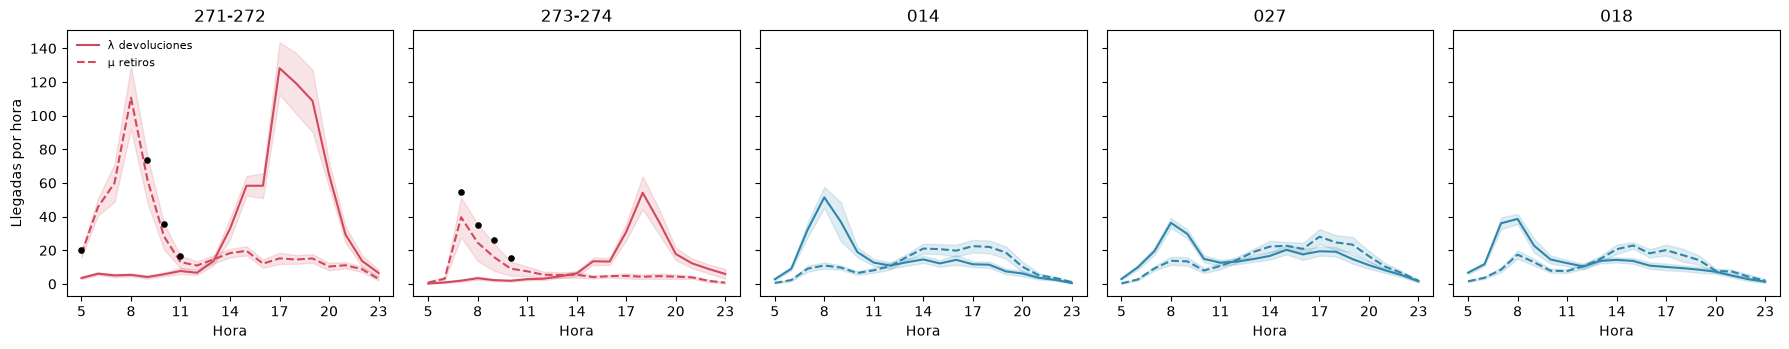

Ancho medio del IC 95 % (horas con 5 o más llegadas): ±17% de la tasa. El error estándar entre días es 1.4 veces el que daría Poisson.


In [5]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
for a, est in zip(ax, ORDEN):
    for proceso, ls, nombre in [("devolucion", "-", "λ devoluciones"), ("retiro", "--", "μ retiros")]:
        t = tasas[(tasas.estacion == est) & (tasas.proceso == proceso)].set_index("hora")
        c = COLORES[SUBRED[est]]
        a.plot(t.index, t.tasa_obs, color=c, ls=ls, label=nombre)
        a.fill_between(t.index, t.ic_inf, t.ic_sup, color=c, alpha=0.15)
        a.scatter(t.index[t.hueco], t.tasa[t.hueco], color="black", s=14, zorder=3)
    a.set_title(est); a.set_xlabel("Hora"); a.set_xticks(range(5, 24, 3))
ax[0].set_ylabel("Llegadas por hora"); ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(DIR_FIG / "modelo_tasas_ic.png", dpi=150, bbox_inches="tight"); plt.show()

r = tasas[tasas.tasa_obs >= 5]
print(f"Ancho medio del IC 95 % (horas con 5 o más llegadas): ±{(1.96 * r.ee / r.tasa_obs).median():.0%} de la tasa. "
      f"El error estándar entre días es {(r.ee / r.ee_poisson).median():.1f} veces el que daría Poisson.")

**Resultados**

- La mitad de las tasas (horas con 5 o más llegadas) tiene un IC de 95 % de ±17 % o menos. El error estándar entre días es 1.4 veces el de Poisson: la variación entre días agrega incertidumbre.
- 10 horas tienen ceros de más. En 8 se corrige la tasa, todas de retiros en Buenavista en la mañana: la 271-272 a las 5 h y de 9 a 11 h, y la 273-274 de 7 a 10 h.
- En la 271-272 de 9 a 11 h, cuando la estación registra cero retiros, las vecinas tienen entre 1.9 y 2.6 veces más retiros de lo normal: la gente se va a la de al lado porque esta no tiene bicis.
- Dos horas no se corrigen porque las vecinas también bajan: la 014 a las 7 h y las devoluciones de la 273-274 a las 22 h.
- La 271-272 a las 5 h queda corregida por poco: sus vecinas bajan (razón 0.37), pero con solo 11 intervalos en cero la prueba no llega a 0.05 (p = 0.06).
- Frente a la versión anterior (13 horas hueco con Poisson), 3 horas dejan de ser hueco al considerar los lotes y 2 se descartan con las vecinas.

### 1.4 Funciones del modelo

- `generador`: matriz $Q$ de una hora con lotes de media $b$, y la tasa de rechazo en cada estado. Para devoluciones, $\lambda(h)\,(1 - 1/b)^{N-n}$ bicis por hora no caben; para retiros, $\mu(h)\,(1 - 1/b)^{n}$ personas por hora se quedan sin bici. Con $b = 1$ queda $\lambda(h)$ solo en $n = N$ y $\mu(h)$ solo en $n = 0$.
- `resolver_dia`: Kolmogorov hora por hora, en pasos de un minuto. Con `x0=None` resuelve todos los arranques a la vez. `reinicios` deja la estación en un nivel dado (visita de camión).

In [6]:
def tasas_estacion(est):
    """λ por hora (devoluciones), μ por hora (retiros) y docks de una estación."""
    t = tasas[tasas.estacion == est].pivot(index="hora", columns="proceso", values="tasa").reindex(HORAS).fillna(0)
    return t["devolucion"].to_numpy(), t["retiro"].to_numpy(), int(DOCKS[est])

def lotes_estacion(est):
    """Tamaño medio de lote de devoluciones y de retiros."""
    return B[(est, "devolucion")], B[(est, "retiro")]

def generador(lam, mu, N, b_dev=1.0, b_ret=1.0):
    """Generador Q con lotes geométricos (media b; b = 1 es una bici a la vez) y tasa de rechazo en cada estado."""
    n = np.arange(N + 1)
    salto = n[None, :] - n[:, None]                                  # j - i
    Q = np.zeros((N + 1, N + 1))
    for tasa, b, signo, borde in [(lam, b_dev, 1, N), (mu, b_ret, -1, 0)]:
        q, k = 1 / b, signo * salto                                   # k = tamaño del salto en el sentido del proceso
        pk = np.where(k >= 1, q * (1 - q) ** np.clip(k - 1, 0, None), 0.0)       # P(lote = k)
        cola = np.where(k >= 1, (1 - q) ** np.clip(k - 1, 0, None), 0.0)         # P(lote >= k): se queda en el borde
        Q += (tasa / b) * np.where(n[None, :] == borde, cola, pk)
    np.fill_diagonal(Q, 0)
    Q -= np.diag(Q.sum(axis=1))
    rech_dev = lam * (1 - 1 / b_dev) ** (N - n)                       # bicis que no caben, por unidad de tiempo
    rech_ret = mu * (1 - 1 / b_ret) ** n                              # retiros sin bici
    return Q, rech_dev, rech_ret

def resolver_dia(lam_h, mu_h, N, x0, b_dev=1.0, b_ret=1.0, pasos_por_hora=60, reinicios=None):
    """Kolmogorov hacia adelante hora por hora, desde las 5:00 con x0 bicis.
    x0 puede ser un entero o None (todos los arranques a la vez: cada fila de P es un arranque).
    reinicios = {paso: nivel} deja la estación en ese nivel (visita del camión)."""
    reinicios, dt = reinicios or {}, 1 / pasos_por_hora
    p = np.eye(N + 1) if x0 is None else np.eye(N + 1)[x0]
    P, paso = [p], 0
    rech_ret, rech_dev = np.zeros((len(lam_h),) + p.shape[:-1]), np.zeros((len(lam_h),) + p.shape[:-1])
    for k, (lam, mu) in enumerate(zip(lam_h, mu_h)):
        Q, r_dev, r_ret = generador(lam, mu, N, b_dev, b_ret)
        E = expm(Q * dt)
        for _ in range(pasos_por_hora):
            if paso in reinicios:
                p = P[-1] = np.eye(N + 1)[reinicios[paso]]
            p_sig = p @ E
            rech_ret[k] += (p + p_sig) @ r_ret / 2 * dt
            rech_dev[k] += (p + p_sig) @ r_dev / 2 * dt
            p = p_sig
            P.append(p)
            paso += 1
    return {"P": np.array(P), "rech_ret": rech_ret, "rech_dev": rech_dev}

def por_hora(P):
    """Promedio de cada hora de la distribución minuto a minuto."""
    return P[1:].reshape(len(HORAS), -1, *P.shape[1:]).mean(axis=1)

## 2. Medidas de falla

Rechazos esperados en un día según el arranque, $R(x_0)$, y el mejor arranque sin camión, $x_0^*$. Con él se calcula la probabilidad de estar vacía o llena en cada hora. Una hora es crítica si tiene 5 o más rechazos esperados.

In [7]:
def rango_horas(horas):
    """[7, 8, 9, 11] -> '7–9, 11 h'."""
    if len(horas) == 0:
        return "—"
    grupos, ini = [], horas[0]
    for a, b in zip(horas, list(horas[1:]) + [None]):
        if b != a + 1:
            grupos.append(f"{ini}–{a}" if a > ini else f"{a}")
            ini = b
    return ", ".join(grupos) + " h"

# R(x0) para todos los arranques a la vez
filas = []
for est in ORDEN:
    lam_h, mu_h, N = tasas_estacion(est)
    r = resolver_dia(lam_h, mu_h, N, None, *lotes_estacion(est))
    filas.append(pd.DataFrame({"estacion": est, "x0": np.arange(N + 1),
                               "sin_bici": r["rech_ret"].sum(0), "sin_dock": r["rech_dev"].sum(0)}))
rechazos = pd.concat(filas, ignore_index=True).assign(total=lambda d: d.sin_bici + d.sin_dock)
rechazos.round(2).to_csv(DIR_TABLAS / "rechazos_x0.csv", index=False)

# Mejor arranque y, con él, probabilidades y rechazos por hora
filas, prob_hora = [], {}
for est in ORDEN:
    lam_h, mu_h, N = tasas_estacion(est)
    x0 = int(rechazos.loc[rechazos[rechazos.estacion == est].total.idxmin(), "x0"])
    r = resolver_dia(lam_h, mu_h, N, x0, *lotes_estacion(est))
    ph = por_hora(r["P"])
    prob_hora[est] = pd.DataFrame({"P_vacia": ph[:, 0], "P_llena": ph[:, N]}, index=HORAS)
    total = r["rech_ret"].sum() + r["rech_dev"].sum()
    filas.append({"estación": est, "grupo": SUBRED[est], "docks": N, "x0*": x0,
                  "sin bici": r["rech_ret"].sum(), "sin dock": r["rech_dev"].sum(), "total": total,
                  "% de la demanda": 100 * total / (lam_h.sum() + mu_h.sum()),
                  "horas críticas sin bici": rango_horas(list(HORAS[r["rech_ret"] >= 5])),
                  "horas críticas sin dock": rango_horas(list(HORAS[r["rech_dev"] >= 5]))})

mejor_x0 = pd.DataFrame(filas).set_index("estación")
mejor_x0.round(1).to_csv(DIR_TABLAS / "mejor_x0.csv")
pd.concat(prob_hora, names=["estacion", "hora"]).round(4).to_csv(DIR_TABLAS / "prob_falla_hora.csv")
print(f"Rechazos totales de la subred con el mejor arranque: {mejor_x0.total.sum():,.0f} por día")
mejor_x0.round(1)

Rechazos totales de la subred con el mejor arranque: 1,089 por día


,grupo,docks,x0*,sin bici,sin dock,total,% de la demanda,horas críticas sin bici,horas críticas sin dock
estación,,,,,,,,,
271-272,Buenavista,74,74,262.4,425.6,688.1,57.6,7–12 h,16–22 h
273-274,Buenavista,70,70,66.8,95.6,162.4,39.3,8–11 h,18–23 h
014,Reforma,39,0,32.1,84.3,116.4,23.7,18–19 h,8–11 h
027,Reforma,43,0,17.1,31.5,48.6,8.7,—,9–10 h
018,Reforma,39,0,22.9,50.6,73.5,15.7,18–19 h,8–11 h


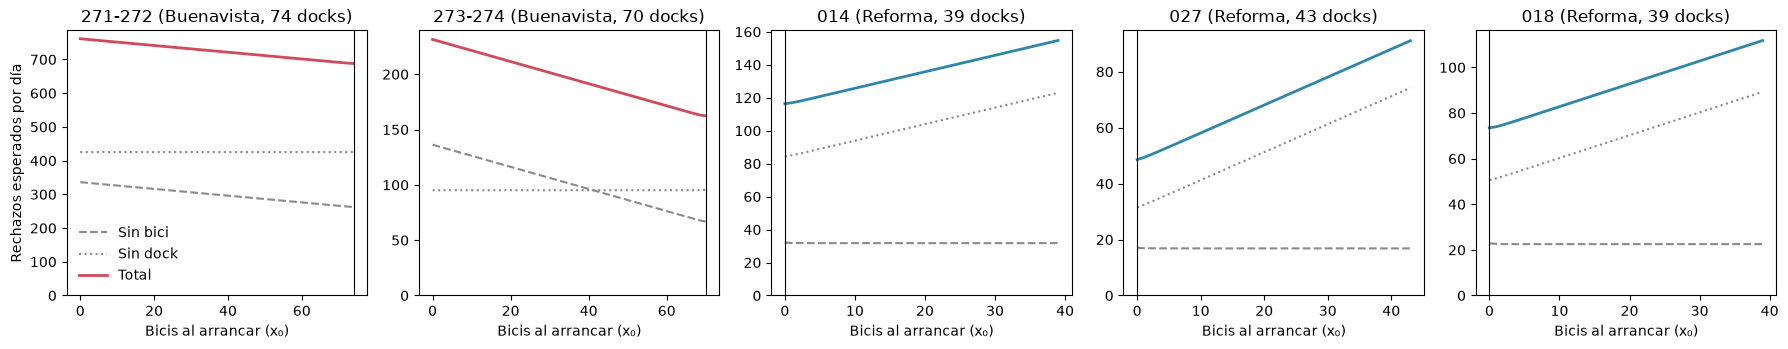

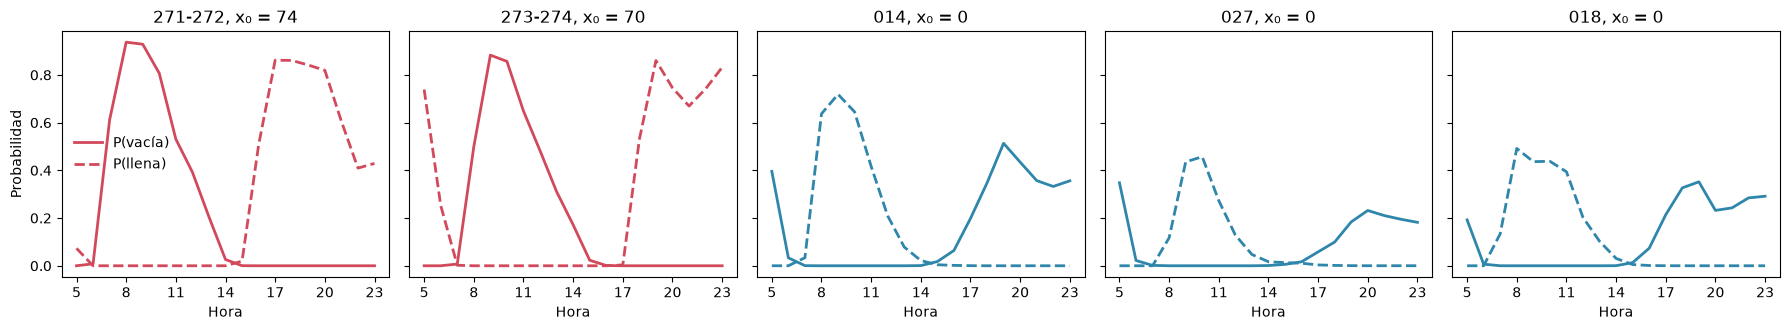

In [8]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.6))
for a, est in zip(ax, ORDEN):
    r = rechazos[rechazos.estacion == est]
    a.plot(r.x0, r.sin_bici, color="#8a8a8a", ls="--", label="Sin bici")
    a.plot(r.x0, r.sin_dock, color="#8a8a8a", ls=":", label="Sin dock")
    a.plot(r.x0, r.total, color=COLORES[SUBRED[est]], lw=2, label="Total")
    a.axvline(mejor_x0.loc[est, "x0*"], color="black", lw=0.8)
    a.set_title(f"{est} ({SUBRED[est]}, {mejor_x0.loc[est, 'docks']} docks)")
    a.set_xlabel("Bicis al arrancar (x₀)"); a.set_ylim(bottom=0)
ax[0].set_ylabel("Rechazos esperados por día"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(DIR_FIG / "modelo_rechazos_x0.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 5, figsize=(18, 3.4), sharey=True)
for a, est in zip(ax, ORDEN):
    p, c = prob_hora[est], COLORES[SUBRED[est]]
    a.plot(HORAS, p.P_vacia, color=c, lw=2, label="P(vacía)")
    a.plot(HORAS, p.P_llena, color=c, lw=2, ls="--", label="P(llena)")
    a.set_title(f"{est}, x₀ = {mejor_x0.loc[est, 'x0*']}"); a.set_xlabel("Hora"); a.set_xticks(range(5, 24, 3))
ax[0].set_ylabel("Probabilidad"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(DIR_FIG / "modelo_prob_falla_hora.png", dpi=150, bbox_inches="tight"); plt.show()

**Resultados**

- El mejor arranque es un extremo: Buenavista llena (74 y 70 bicis) y Reforma vacía.
- $R(x_0)$ es casi una recta. Cada bici de más al arrancar evita o agrega un rechazo de la primera falla del día; la segunda no depende de $x_0$ porque para entonces la estación ya tocó el otro extremo.
- Aun así quedan 1,089 rechazos por día: 688 en la 271-272 (58 % de su demanda), 162 en la 273-274, 116 en la 014, 74 en la 018 y 49 en la 027.
- Buenavista falla por vacía en la mañana (7 a 12 h) y por llena de la tarde al cierre (16 a 23 h). Reforma falla por llena de 8 a 11 h y, en la 014 y la 018, por vacía de 18 a 19 h.
- Ningún arranque evita los rechazos: hace falta mover bicis durante el día (Etapa 3, `camion.ipynb`). Estos números son sin camión; no son los rechazos reales de hoy.

## 3. Validación

1. Monte Carlo contra Kolmogorov (¿la solución numérica es correcta?).
2. Horas hueco contra el modelo (¿el modelo predice estación vacía donde los datos lo sugieren?).
3. Otros meses (¿las conclusiones de vacía y llena se repiten fuera de septiembre?).
4. Efecto de los lotes en los rechazos.

### 3.1 Monte Carlo

Se simulan 1,000 días de la 271-272 evento por evento (algoritmo de Gillespie, con lotes): el tiempo al siguiente lote es exponencial, se elige si es devolución o retiro y se sortea su tamaño. En cada minuto se cuenta en cuántos de los 1,000 días la estación está vacía (o llena); la probabilidad estimada es ese conteo entre 1,000, con IC binomial de 95 %, $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/1000}$.

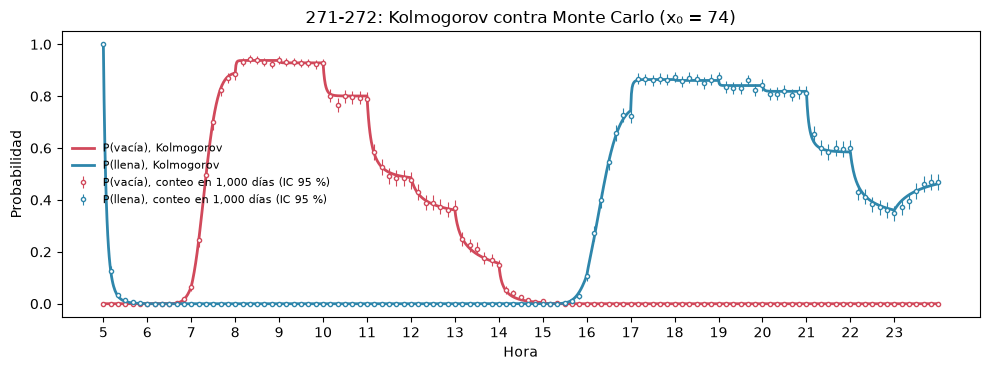

Diferencia máxima entre conteo y Kolmogorov en P(vacía): 0.045 (minuto a minuto)
Rechazos del día en 271-272: Kolmogorov 688.1 | Monte Carlo 686.2 (IC 95 %: 683.6 a 688.8)


In [9]:
def simular_dia(lam_h, mu_h, N, x0, b_dev, b_ret, rng, pasos=60):
    """Un día simulado evento por evento (con lotes). Devuelve el número de bicis en cada minuto y los rechazos."""
    x, rech, j = x0, 0, 1
    estado = np.empty(len(lam_h) * pasos + 1, dtype=int)
    estado[0] = x0
    for lam, mu in zip(lam_h, mu_h):
        g_dev, g_ret = lam / b_dev, mu / b_ret                       # tasa de lotes
        t, marca = 0.0, 1
        while True:
            dt = rng.exponential(1 / (g_dev + g_ret)) if g_dev + g_ret > 0 else np.inf
            while marca <= pasos and marca / pasos <= t + dt:         # minutos que pasan antes del siguiente evento
                estado[j] = x; j += 1; marca += 1
            if t + dt >= 1:
                break
            t += dt
            if rng.random() < g_dev / (g_dev + g_ret):
                k = rng.geometric(1 / b_dev); entra = min(k, N - x); x += entra
            else:
                k = rng.geometric(1 / b_ret); entra = min(k, x); x -= entra
            rech += k - entra
    return estado, rech

EST_SIM, N_SIM = "271-272", 1000
rng = np.random.default_rng(2026)
lam_h, mu_h, N = tasas_estacion(EST_SIM)
x0 = int(mejor_x0.loc[EST_SIM, "x0*"])
sims = [simular_dia(lam_h, mu_h, N, x0, *lotes_estacion(EST_SIM), rng) for _ in range(N_SIM)]
estados = np.array([s[0] for s in sims]); rech_sim = np.array([s[1] for s in sims])

# Probabilidad por conteo: en cada minuto, cuántos de los 1,000 días la estación está vacía (o llena)
kolm = resolver_dia(lam_h, mu_h, N, x0, *lotes_estacion(EST_SIM))["P"]
t_min = 5 + np.arange(estados.shape[1]) / 60
fig, ax = plt.subplots(figsize=(10, 3.8))
for nombre, nivel, c in [("vacía", 0, "#d1495b"), ("llena", N, "#2e86ab")]:
    cuenta = (estados == nivel).sum(axis=0)
    p_mc = cuenta / N_SIM
    ee = np.sqrt(p_mc * (1 - p_mc) / N_SIM)
    ax.plot(t_min, kolm[:, nivel], color=c, lw=2, label=f"P({nombre}), Kolmogorov")
    cada = slice(0, None, 10)
    ax.errorbar(t_min[cada], p_mc[cada], yerr=1.96 * ee[cada], fmt="o", ms=3, color=c, mfc="white",
                elinewidth=0.8, label=f"P({nombre}), conteo en {N_SIM:,} días (IC 95 %)")
ax.set_xlabel("Hora"); ax.set_ylabel("Probabilidad"); ax.set_xticks(HORAS)
ax.set_title(f"{EST_SIM}: Kolmogorov contra Monte Carlo (x₀ = {x0})"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(DIR_FIG / "modelo_validacion_simulacion.png", dpi=150, bbox_inches="tight"); plt.show()

dif = np.abs((estados == 0).mean(0) - kolm[:, 0])
ic = 1.96 * rech_sim.std(ddof=1) / np.sqrt(N_SIM)
print(f"Diferencia máxima entre conteo y Kolmogorov en P(vacía): {dif.max():.3f} (minuto a minuto)")
print(f"Rechazos del día en {EST_SIM}: Kolmogorov {mejor_x0.loc[EST_SIM, 'total']:.1f} | "
      f"Monte Carlo {rech_sim.mean():.1f} (IC 95 %: {rech_sim.mean() - ic:.1f} a {rech_sim.mean() + ic:.1f})")

**Resultados**

- Los conteos caen sobre la curva de Kolmogorov en todo el día. La mayor diferencia minuto a minuto es 0.045, del orden del error de Monte Carlo con 1,000 días.
- Rechazos del día: 688.1 con Kolmogorov y 686.2 con Monte Carlo (IC 95 %: 683.6 a 688.8). La solución numérica es correcta.

### 3.2 Horas hueco contra el modelo

En las 8 horas hueco los datos sugieren estación vacía. Se revisa la probabilidad de estación vacía que da el modelo en esa hora, arrancando en $x_0^*$.

In [10]:
# Horas hueco confirmadas contra la probabilidad de falla que da el modelo en esa hora (arrancando en x0*)
filas = []
for est, h, proceso in tasas.loc[tasas.hueco, ["estacion", "hora", "proceso"]].itertuples(index=False):
    falla = "vacía" if proceso == "retiro" else "llena"
    p = prob_hora[est].loc[h, "P_vacia" if falla == "vacía" else "P_llena"]
    filas.append({"estación": est, "hora": h, "proceso": proceso, "el hueco sugiere estación": falla,
                  "P en el modelo": round(p, 2), "coincide (P ≥ 0.5)": "sí" if p >= 0.5 else "no"})
consistencia = pd.DataFrame(filas).sort_values(["estación", "hora"]).reset_index(drop=True)
consistencia.to_csv(DIR_TABLAS / "validacion_huecos.csv", index=False)
print(f"Coinciden {(consistencia['coincide (P ≥ 0.5)'] == 'sí').sum()} de {len(consistencia)} horas hueco.")
consistencia

Coinciden 5 de 8 horas hueco.


,estación,hora,proceso,el hueco sugiere estación,P en el modelo,coincide (P ≥ 0.5)
0,271-272,5,retiro,vacía,0.00,no
1,271-272,9,retiro,vacía,0.93,sí
2,271-272,10,retiro,vacía,0.81,sí
3,271-272,11,retiro,vacía,0.53,sí
4,273-274,7,retiro,vacía,0.01,no
5,273-274,8,retiro,vacía,0.50,no
6,273-274,9,retiro,vacía,0.88,sí
7,273-274,10,retiro,vacía,0.86,sí


**Resultados**

- Coinciden 5 de 8: la 271-272 de 9 a 11 h y la 273-274 a las 9 y 10 h, con probabilidades de 0.53 a 0.93.
- La 273-274 a las 8 h queda justo en el límite (0.50).
- La 271-272 a las 5 h y la 273-274 a las 7 h no coinciden porque el modelo arranca lleno (el mejor caso). En la realidad la estación arranca con lo que dejó el camión, que puede ser mucho menos.

### 3.3 Otros meses

Se corre el mismo modelo con las tasas observadas de cada uno de los 13 meses (sin corregir huecos) y su propio $x_0^*$. El mapa muestra $P(\text{vacía}) - P(\text{llena})$ por hora: rojo es vacía, azul es llena. La tabla da, para la falla de la mañana y la de la tarde de cada estación, el rango entre meses de su probabilidad máxima y de la hora en que ocurre.

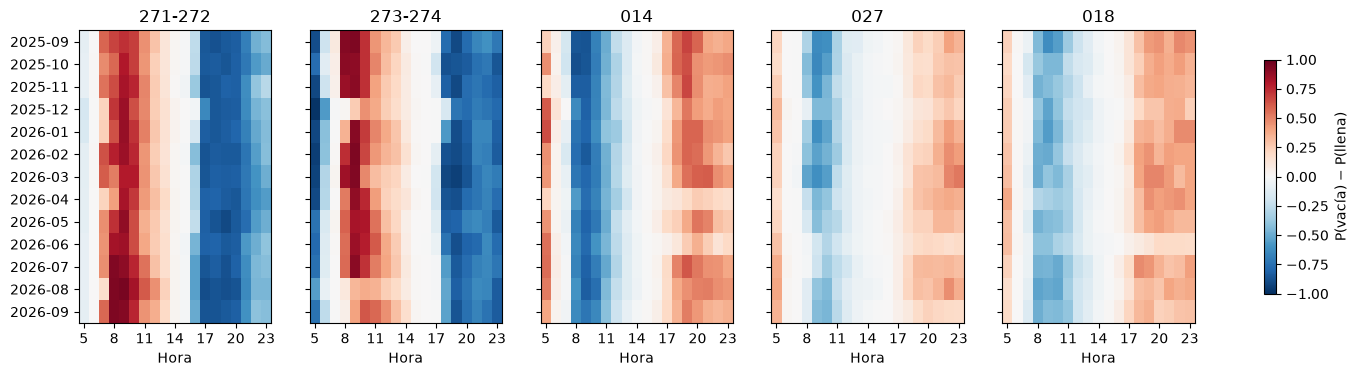

13 meses: 2025-09 a 2026-09


,falla mañana / tarde,P_manana_min,P_manana_max,hora_manana,P_tarde_min,P_tarde_max,hora_tarde
estacion,,,,,,,
271-272,vacía / llena,0.73,0.95,8–10 h,0.84,0.90,17–20 h
273-274,vacía / llena,0.37,0.93,8–10 h,0.78,0.93,18–23 h
014,llena / vacía,0.72,0.88,8–9 h,0.25,0.67,19–21 h
027,llena / vacía,0.29,0.65,9–10 h,0.21,0.53,20–23 h
018,llena / vacía,0.35,0.62,8–10 h,0.20,0.49,18–23 h


In [11]:
# Mismo modelo con las tasas observadas de cada uno de los 12 meses (sin corrección de huecos)
cols = ["Ciclo_Estacion_Retiro", "Ciclo_EstacionArribo", "retiro", "arribo", "es_habil", "en_horario", "hora_arribo",
        "retiro_subred", "arribo_subred", "mes", "fecha"]
d12 = pd.read_parquet("data/clean/trips_12m.parquet", columns=cols)
habiles = set(d12.loc[d12.es_habil, "fecha"].unique())
ret12 = d12[d12.es_habil & d12.en_horario & d12.retiro_subred]
dev12 = d12[d12.arribo_subred & d12.arribo.dt.normalize().isin(habiles) & d12.hora_arribo.between(5, 23)]
n_mes = d12[d12.es_habil].groupby("mes", observed=True).fecha.nunique()
c_ret = ret12.groupby([ret12.retiro.dt.strftime("%Y-%m").rename("mes"), ret12.Ciclo_Estacion_Retiro.astype(str).rename("est"),
                       ret12.retiro.dt.hour.rename("hora")]).size()
c_dev = dev12.groupby([dev12.arribo.dt.strftime("%Y-%m").rename("mes"), dev12.Ciclo_EstacionArribo.astype(str).rename("est"),
                       dev12.arribo.dt.hour.rename("hora")]).size()
del d12, ret12, dev12

MESES = [str(m) for m in n_mes.index]
mapa = {est: np.zeros((len(MESES), len(HORAS))) for est in ORDEN}
filas = []
for i, mes in enumerate(MESES):
    for est in ORDEN:
        tasa = lambda c: c.get(mes, pd.Series(dtype=float)).get(est, pd.Series(dtype=float)).reindex(HORAS, fill_value=0).to_numpy() / n_mes.iloc[i]
        lam_h, mu_h, N = tasa(c_dev), tasa(c_ret), int(DOCKS[est])
        r = resolver_dia(lam_h, mu_h, N, None, *lotes_estacion(est))
        x0 = int(np.argmin(r["rech_ret"].sum(0) + r["rech_dev"].sum(0)))
        ph = por_hora(r["P"])[:, x0, :]
        mapa[est][i] = ph[:, 0] - ph[:, N]
        man, tar = (HORAS >= 6) & (HORAS <= 12), HORAS >= 15
        f_man, f_tar = (0, N) if SUBRED[est] == "Buenavista" else (N, 0)   # Buenavista: vacía en la mañana, llena en la tarde
        filas.append({"mes": mes, "estacion": est, "x0*": x0,
                      "P mañana": ph[man, f_man].max(), "hora mañana": int(HORAS[man][ph[man, f_man].argmax()]),
                      "P tarde": ph[tar, f_tar].max(), "hora tarde": int(HORAS[tar][ph[tar, f_tar].argmax()])})
meses_tab = pd.DataFrame(filas)
meses_tab.to_csv(DIR_TABLAS / "validacion_meses.csv", index=False)

fig, ax = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
for a, est in zip(ax, ORDEN):
    im = a.imshow(mapa[est], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    a.set_xticks(range(0, len(HORAS), 3)); a.set_xticklabels(HORAS[::3]); a.set_title(est); a.set_xlabel("Hora")
ax[0].set_yticks(range(len(MESES))); ax[0].set_yticklabels(MESES)
fig.colorbar(im, ax=ax, shrink=0.8, label="P(vacía) − P(llena)")
fig.savefig(DIR_FIG / "modelo_validacion_meses.png", dpi=150, bbox_inches="tight"); plt.show()

rango = lambda s: f"{s.min()}–{s.max()} h"
resumen_meses = meses_tab.groupby("estacion").agg(
    P_manana_min=("P mañana", "min"), P_manana_max=("P mañana", "max"), hora_manana=("hora mañana", rango),
    P_tarde_min=("P tarde", "min"), P_tarde_max=("P tarde", "max"), hora_tarde=("hora tarde", rango)).reindex(ORDEN)
resumen_meses.insert(0, "falla mañana / tarde", ["vacía / llena" if SUBRED[e] == "Buenavista" else "llena / vacía" for e in ORDEN])
print(f"{len(MESES)} meses: {MESES[0]} a {MESES[-1]}")
resumen_meses.round(2)

**Resultados**

- El patrón de septiembre 2026 aparece en los 13 meses: Buenavista vacía de 8 a 10 h y llena de 17 a 23 h; Reforma llena de 8 a 10 h y con algo de falta de bicis en la noche.
- Las horas pico casi no cambian. Lo que cambia es la intensidad: la 271-272 tiene $P$(vacía) máxima entre 0.73 y 0.95 según el mes; la 027 y la 018 son las más variables (P(llena) entre 0.29 y 0.65).
- La franja azul a las 5 h en la 273-274 es por el arranque lleno, no por demanda.
- Las conclusiones de estación vacía y llena no son propias de septiembre.

### 3.4 Efecto de los lotes

Mismos $x_0^*$ y mismas tasas, con lotes ($b$ estimado) y sin lotes ($b = 1$).

In [12]:
# ¿Cuánto cambian los rechazos por modelar los lotes? (mismo x0*, mismas tasas)
filas = []
for est in ORDEN:
    lam_h, mu_h, N = tasas_estacion(est)
    x0 = int(mejor_x0.loc[est, "x0*"])
    sin = resolver_dia(lam_h, mu_h, N, x0)
    filas.append({"estación": est, "rechazos sin lotes (b = 1)": sin["rech_ret"].sum() + sin["rech_dev"].sum(),
                  "rechazos con lotes": mejor_x0.loc[est, "total"]})
sens = pd.DataFrame(filas).set_index("estación")
sens["diferencia %"] = 100 * (sens["rechazos con lotes"] / sens["rechazos sin lotes (b = 1)"] - 1)
sens.round(1)

,rechazos sin lotes (b = 1),rechazos con lotes,diferencia %
estación,,,
271-272,684.3,688.1,0.6
273-274,160.7,162.4,1.1
014,115.0,116.4,1.2
027,47.4,48.6,2.5
018,72.3,73.5,1.6


**Resultados**

- Con lotes hay entre 0.6 % y 2.5 % más rechazos. Los lotes importan para detectar bien los huecos (sección 1.3), pero casi no cambian las medidas de falla.

## 4. Supuestos

| # | Supuesto | Cómo se contrastó | Resultado |
|---|---|---|---|
| 1 | Llegadas Poisson dentro de cada hora | Prueba exacta de CV por Monte Carlo y KS sobre la posición en la hora (1.1) | Aproximado: CV mediano de 0.97 a 1.07, pero las pruebas rechazan más de lo esperado, sobre todo en Buenavista |
| 2 | Una bici a la vez | Exceso de tiempos entre llegadas de 20 s o menos (1.2) | No se cumple en Buenavista ($b$ hasta 1.37). Se modela con lotes geométricos |
| 3 | Tasa constante dentro de la hora | KS de la posición dentro de la hora (1.1) | Aproximado: D ≤ 0.076 |
| 4 | Todos los días hábiles tienen la misma tasa | Dispersión entre días y error estándar (1.1, 1.3) | No se cumple: dispersión de 1.25 a 7.58. El modelo describe un día típico; la variación va a escenarios (Etapa 4) |
| 5 | La demanda observada es la real, salvo en horas hueco | Ceros de más frente al modelo con lotes y comparación con estaciones vecinas (1.3) | 8 horas corregidas, todas de retiros en Buenavista en la mañana |
| 6 | Capacidad N = docks del feed | No se puede contrastar con los viajes | Se usa el feed actual |
| 7 | Estaciones independientes | No se contrastó | Pendiente: matriz origen-destino (`eda_b.ipynb`, sección 15) |
| 8 | El usuario rechazado se pierde | Estaciones vecinas (1.3) | Para la estación sí se pierde; pero parte de esos usuarios usa la vecina, así que para el sistema el viaje no siempre se pierde |
| 9 | Sin camión durante el día | Por construcción | El camión es la Etapa 3 (`camion.ipynb`) |
| 10 | El patrón de septiembre es representativo | Modelo con cada uno de 13 meses (3.3) | Se cumple: mismas fallas a las mismas horas en todos los meses |

Límites:
- El modelo describe un día típico; en días de mucha demanda habrá más rechazos.
- La corrección de huecos sigue siendo una aproximación: puede quedarse corta (un intervalo vacío solo parte del tiempo cuenta como "con actividad") o alta (los intervalos con actividad vienen más de los días de mucha demanda).
- Los umbrales (8 por hora, 10 puntos de ceros, 150 m, 20 s, 5 rechazos para hora crítica) son decisiones del equipo.

## 5. Resumen

1. Qué representa: cada estación es una cadena de Markov con estados $0, \dots, N$ (bicis ancladas). Las devoluciones suben el estado y los retiros lo bajan, en lotes de tamaño geométrico; con lotes de una bici es un proceso de nacimiento y muerte truncado en $N$. Se resuelve con Kolmogorov hora por hora.
2. Qué supone: tabla de la sección 4.
3. Parámetros: $\hat\lambda(h)$ y $\hat\mu(h)$ por estación y hora (media de 19 días, IC de 95 % con el error entre días), $b$ por estación y proceso (de 1.04 a 1.37), y $N$ = docks. Se corrigen 8 horas hueco.
4. Qué produce: probabilidad de estación vacía y llena por hora, rechazos esperados y mejor arranque. Sin camión quedan 1,089 rechazos por día en la subred.
5. Validación: Monte Carlo coincide con Kolmogorov; el modelo predice estación vacía en 5 de las 8 horas hueco; el patrón se repite en los 13 meses.